Section 1: Problem Statement & App Value Proposition
Value Proposition: For Heat Exchanger Design Engineers and chemical engineering students who need to calculate required heat exchanger surface areas and outlet stream temperatures, my app is a heat exchanger rating solver and temperature profile visualizer built using Tkinter. Unlike performing manual LMTD correction calculations or Excel formulas, my app plots fluid temperature profiles along the exchanger length, evaluates overall heat transfer coefficients, and flags physical temperature cross conditions in real time.
Process thermal engineers and chemical engineering students frequently need to size heat exchangers, compute Logarithmic Mean Temperature Differences (LMTD), and evaluate heat transfer surface area requirements for counter-current and co-current exchanger configurations. Performing these thermal calculations manually requires repetitive unit conversions and iterative evaluations of correction-factor formulas, which are prone to error. While taking CHEE 405: Heat Transfer and performing these calculations, I would spend an average of 2-3 hours searching for equations, correction factors, converting units, and performing calculations.

Section 2: Project Description & Engineering Basis

Engineering Basis: Heat exchanger sizing relies on the fundamental heat transfer rate equation:
   $$Q = U \cdot A \cdot \Delta T_{lm,eff} = U \cdot A \cdot (F_T \cdot \text{LMTD})$$
where $Q$ is heat duty (W), $U$ is the overall heat transfer coefficient ($\text{W/m}^2\cdot\text{°C}$), $A$ is the required heat transfer surface area ($\text{m}^2$), $F_T$ is the multi-pass correction factor, and LMTD is the logarithmic mean temperature difference:
   $$\text{LMTD} = \frac{\Delta T_1 - \Delta T_2}{\ln(\Delta T_1 / \Delta T_2)}$$
For 1-shell pass, 2-tube pass exchangers, $F_T$ is computed analytically from temperature effectiveness ($P$) and capacity ratio ($R$):
   $$P = \frac{T_{c,out} - T_{c,in}}{T_{h,in} - T_{c,in}}, \quad R = \frac{T_{h,in} - T_{h,out}}{T_{c,out} - T_{c,in}}$$
   Counter-Current Flow: Hot and cold fluids enter from opposite ends and flow in reverse directions. The terminal temperature differences are defined as:
   $$\Delta T_1 = T_{h,in} - T_{c,out} \quad \text{and} \quad \Delta T_2 = T_{h,out} - T_{c,in}$$
Counter-current operation maintains a relatively uniform temperature difference along the entire length of the exchanger, resulting in a higher Logarithmic Mean Temperature Difference ($\text{LMTD}$) and allowing the cold outlet temperature ($T_{c,out}$) to cross above the hot outlet temperature ($T_{h,out}$).   
Co-Current (Parallel) Flow: Both fluids enter from the same end and flow in the same direction. The terminal temperature differences are defined as:
   $$\Delta T_1 = T_{h,in} - T_{c,in} \quad \text{and} \quad \Delta T_2 = T_{h,out} - T_{c,out}$$
In co-current flow, the thermal driving force is large at the inlet but decays rapidly toward the outlet. Thermo-mechanically, the cold stream outlet temperature ($T_{c,out}$) can never exceed the hot stream outlet temperature ($T_{h,out}$).

Operational Goals: The app accepts inputs in various unit systems (°C, °F, K, kW, BTU/hr, W, MW), converts them to base SI units for calculation, evaluates thermal feasibility, flags temperature crosses or pinch conditions, computes effective heat transfer area, renders a $T\text{-}z$ profile graph, and presents outputs in the selected units. 

App Operational Logic: The application evaluates these terminal temperature differences based on the selected flow regime. If co-current flow is selected and $T_{c,out} \ge T_{h,out}$, or if any terminal difference yields $\Delta T \le 0$, the app automatically flags a Temperature Cross / Pinch Condition Warning and halts area calculations to prevent non-physical results.   

![GUI Hand Sketch](heat_exchanger_gui_sketch.png)

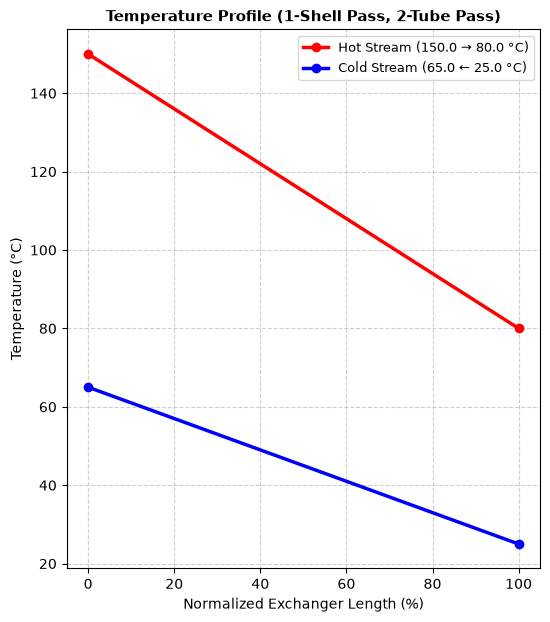

In [12]:
import math
import tkinter as tk
from tkinter import ttk, messagebox
import matplotlib.pyplot as plt
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg


# --- Unit Conversion Helpers ---
def convert_temp_to_celsius(val, unit):
    if unit == "°F":
        return (val - 32.0) * (5.0 / 9.0)
    elif unit == "K":
        return val - 273.15
    return val  # Default °C


def convert_q_to_watts(val, unit):
    if unit == "BTU/hr":
        return val * 0.29307107
    elif unit == "MW":
        return val * 1_000_000.0
    elif unit == "W":
        return val
    return val * 1000.0  # Default kW to Watts


def convert_u_to_si(val, unit):
    if unit == "BTU/hr·ft²·°F":
        return val * 5.678263  # Imperial to W/(m²·°C)
    return val  # Default W/(m²·°C)


def convert_area_from_m2(val_m2, unit):
    if unit == "ft²":
        return val_m2 * 10.7639
    return val_m2  # Default m²


# --- Main Calculation & Plot Logic ---
def calculate_sizing(event=None):
    try:
        temp_unit = combo_temp_unit.get()
        q_unit = combo_q_unit.get()
        u_unit = combo_u_unit.get()
        area_unit = combo_area_unit.get()

        # Read & Convert Temperature Inputs to Base Celsius
        T_h_in_disp = float(entry_Th_in.get())
        T_h_out_disp = float(entry_Th_out.get())
        T_c_in_disp = float(entry_Tc_in.get())
        T_c_out_disp = float(entry_Tc_out.get())

        T_h_in_c = convert_temp_to_celsius(T_h_in_disp, temp_unit)
        T_h_out_c = convert_temp_to_celsius(T_h_out_disp, temp_unit)
        T_c_in_c = convert_temp_to_celsius(T_c_in_disp, temp_unit)
        T_c_out_c = convert_temp_to_celsius(T_c_out_disp, temp_unit)

        # Read & Convert Heat Duty to Base Watts
        Q_val = slider_Q.get()
        Q_duty_watts = convert_q_to_watts(Q_val, q_unit)

        # Read & Convert Overall U Coefficient to Base SI [W/(m²·°C)]
        U_val = slider_U.get()
        U_coeff_si = convert_u_to_si(U_val, u_unit)

        flow_type = combo_flow.get()

        # Input Validation (in Celsius)
        if T_h_in_c <= T_h_out_c:
            lbl_warning.config(
                text="⚠️ ERROR: Hot inlet temp must be greater than hot outlet temp.",
                fg="red",
            )
            return
        if T_c_out_c <= T_c_in_c:
            lbl_warning.config(
                text="⚠️ ERROR: Cold outlet temp must be greater than cold inlet temp.",
                fg="red",
            )
            return

        # Calculate Temperature Differences for Counter-Current vs Co-Current
        dT1 = T_h_in_c - T_c_out_c
        dT2 = T_h_out_c - T_c_in_c

        if flow_type == "Co-Current":
            dT1 = T_h_in_c - T_c_in_c
            dT2 = T_h_out_c - T_c_out_c

        # Check for Temperature Cross
        if dT1 <= 0 or dT2 <= 0:
            lbl_warning.config(
                text="⚠️ WARNING: Temperature Cross Detected!\nHeat exchanger cannot operate under these conditions.",
                fg="red",
            )
            lbl_lmtd.config(text=f"LMTD: -- {temp_unit}")
            lbl_ft.config(text="Correction Factor (Ft): --")
            lbl_area.config(text=f"Required Area: -- {area_unit}")
            return

        # Calculate Counter-Current LMTD (Delta T in °C or K)
        if abs(dT1 - dT2) < 1e-5:
            lmtd_c = dT1
        else:
            lmtd_c = (dT1 - dT2) / math.log(dT1 / dT2)

        # Format LMTD Output Display Value
        lmtd_disp = lmtd_c * 1.8 if temp_unit == "°F" else lmtd_c

        # Calculate Correction Factor (Ft) for Multi-Pass Shell & Tube
        Ft = 1.0
        if flow_type == "1-Shell Pass, 2-Tube Pass":
            denom_P = T_h_in_c - T_c_in_c
            if denom_P == 0:
                lbl_warning.config(
                    text="⚠️ ERROR: Invalid temperature differential.", fg="red"
                )
                return

            P = (T_c_out_c - T_c_in_c) / denom_P
            R = (
                (T_h_in_c - T_h_out_c) / (T_c_out_c - T_c_in_c)
                if (T_c_out_c != T_c_in_c)
                else 1.0
            )

            if R != 1.0:
                sqrt_val = math.sqrt(R**2 + 1)
                num = sqrt_val * math.log((1 - P) / (1 - P * R))
                den_term = (2 - P * (R + 1 - sqrt_val)) / (
                    2 - P * (R + 1 + sqrt_val)
                )

                if den_term <= 0 or (1 - P * R) <= 0 or (1 - P) <= 0:
                    lbl_warning.config(
                        text="⚠️ WARNING: Pinch condition in shell-and-tube pass!",
                        fg="red",
                    )
                    lbl_lmtd.config(text=f"LMTD: {lmtd_disp:.2f} {temp_unit}")
                    lbl_ft.config(text="Correction Factor (Ft): Invalid")
                    lbl_area.config(text=f"Required Area: -- {area_unit}")
                    return
                Ft = num / ((R - 1) * math.log(den_term))
            else:
                sqrt_2 = math.sqrt(2)
                num = (sqrt_2 * P) / (1 - P)
                den_term = (2 - P * (2 - sqrt_2)) / (2 - P * (2 + sqrt_2))
                if den_term <= 0:
                    lbl_warning.config(
                        text="⚠️ WARNING: Pinch condition in shell-and-tube pass!",
                        fg="red",
                    )
                    return
                Ft = num / math.log(den_term)

            Ft = min(Ft, 1.0)
            if Ft < 0.75:
                lbl_warning.config(
                    text=f"⚠️ WARNING: Low Ft ({Ft:.2f} < 0.75). Thermal design is inefficient!",
                    fg="orange",
                )
            else:
                lbl_warning.config(
                    text="✓ Operational Status: Valid Thermal Profile",
                    fg="green",
                )
        else:
            lbl_warning.config(
                text="✓ Operational Status: Valid Thermal Profile", fg="green"
            )

        # Calculate Area in m²: Area = Q_watts / (U_si * Ft * LMTD_celsius)
        lmtd_eff_c = lmtd_c * Ft
        area_m2 = Q_duty_watts / (U_coeff_si * lmtd_eff_c)

        # Convert Area Output to Selected Display Unit
        area_disp = convert_area_from_m2(area_m2, area_unit)

        # Update Results UI
        lbl_lmtd.config(text=f"LMTD: {lmtd_disp:.2f} {temp_unit}")
        lbl_ft.config(text=f"Correction Factor (Ft): {Ft:.3f}")
        lbl_area.config(text=f"Required Area: {area_disp:.2f} {area_unit}")

        # Update Plot Area
        plot_temperature_profile(
            T_h_in_disp,
            T_h_out_disp,
            T_c_in_disp,
            T_c_out_disp,
            flow_type,
            temp_unit,
        )

    except ValueError:
        lbl_warning.config(
            text="⚠️ Input Error: Please enter valid numbers.", fg="red"
        )


def update_q_slider_range(event=None):
    unit = combo_q_unit.get()
    if unit == "BTU/hr":
        slider_Q.config(from_=10000, to=3000000, resolution=10000)
        slider_Q.set(850000)
    elif unit == "MW":
        slider_Q.config(from_=0.01, to=2.0, resolution=0.01)
        slider_Q.set(0.25)
    elif unit == "W":
        slider_Q.config(from_=10000, to=1000000, resolution=5000)
        slider_Q.set(250000)
    else:  # kW
        slider_Q.config(from_=10, to=1000, resolution=5)
        slider_Q.set(250)
    calculate_sizing()


def update_u_slider_range(event=None):
    unit = combo_u_unit.get()
    if unit == "BTU/hr·ft²·°F":
        slider_U.config(from_=10, to=350, resolution=5)
        slider_U.set(88)
    else:  # W/m²·°C
        slider_U.config(from_=50, to=2000, resolution=10)
        slider_U.set(500)
    calculate_sizing()


def plot_temperature_profile(Th_in, Th_out, Tc_in, Tc_out, flow_type, temp_unit):
    ax.clear()
    z = [0, 100]

    hot_profile = [Th_in, Th_out]
    cold_profile = (
        [Tc_in, Tc_out] if flow_type == "Co-Current" else [Tc_out, Tc_in]
    )

    ax.plot(
        z,
        hot_profile,
        "r-o",
        linewidth=2.5,
        label=f"Hot Stream ({Th_in} → {Th_out} {temp_unit})",
    )
    ax.plot(
        z,
        cold_profile,
        "b-o",
        linewidth=2.5,
        label=(
            f"Cold Stream ({Tc_in} → {Tc_out} {temp_unit})"
            if flow_type == "Co-Current"
            else f"Cold Stream ({Tc_out} ← {Tc_in} {temp_unit})"
        ),
    )

    ax.set_title(
        f"Temperature Profile ({flow_type})", fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("Normalized Exchanger Length (%)", fontsize=10)
    ax.set_ylabel(f"Temperature ({temp_unit})", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="best", fontsize=9)

    canvas.draw()


# --- GUI Layout Setup ---
root = tk.Tk()
root.title("Double-Pipe & Shell-and-Tube Heat Exchanger Sizing and LMTD Correction Solver")
root.geometry("950x720")

frame_inputs = tk.LabelFrame(
    root, text=" Input Parameters & Units ", padx=10, pady=10
)
frame_inputs.pack(side=tk.LEFT, fill=tk.Y, padx=10, pady=10)

# Temperature Unit Selector & Entries
tk.Label(
    frame_inputs, text="Temperature Unit:", font=("Arial", 9, "bold")
).grid(row=0, column=0, sticky="w", pady=3)
combo_temp_unit = ttk.Combobox(
    frame_inputs, values=["°C", "°F", "K"], width=10, state="readonly"
)
combo_temp_unit.grid(row=0, column=1, pady=3, sticky="w")
combo_temp_unit.set("°C")
combo_temp_unit.bind("<<ComboboxSelected>>", calculate_sizing)

tk.Label(frame_inputs, text="Hot Stream Inlet T:").grid(
    row=1, column=0, sticky="w", pady=3
)
entry_Th_in = tk.Entry(frame_inputs, width=10)
entry_Th_in.grid(row=1, column=1, pady=3)
entry_Th_in.insert(0, "150")

tk.Label(frame_inputs, text="Hot Stream Outlet T:").grid(
    row=2, column=0, sticky="w", pady=3
)
entry_Th_out = tk.Entry(frame_inputs, width=10)
entry_Th_out.grid(row=2, column=1, pady=3)
entry_Th_out.insert(0, "80")

tk.Label(frame_inputs, text="Cold Stream Inlet T:").grid(
    row=3, column=0, sticky="w", pady=3
)
entry_Tc_in = tk.Entry(frame_inputs, width=10)
entry_Tc_in.grid(row=3, column=1, pady=3)
entry_Tc_in.insert(0, "25")

tk.Label(frame_inputs, text="Cold Stream Outlet T:").grid(
    row=4, column=0, sticky="w", pady=3
)
entry_Tc_out = tk.Entry(frame_inputs, width=10)
entry_Tc_out.grid(row=4, column=1, pady=3)
entry_Tc_out.insert(0, "65")

# Flow Arrangement
tk.Label(frame_inputs, text="Flow Arrangement:").grid(
    row=5, column=0, sticky="w", pady=3
)
combo_flow = ttk.Combobox(
    frame_inputs,
    values=["Counter-Current", "Co-Current", "1-Shell Pass, 2-Tube Pass"],
    width=22,
    state="readonly",
)
combo_flow.grid(row=5, column=1, pady=3)
combo_flow.set("1-Shell Pass, 2-Tube Pass")
combo_flow.bind("<<ComboboxSelected>>", calculate_sizing)

# Heat Duty Units & Slider
tk.Label(
    frame_inputs, text="Heat Duty (Q) Unit:", font=("Arial", 9, "bold")
).grid(row=6, column=0, sticky="w", pady=(8, 0))
combo_q_unit = ttk.Combobox(
    frame_inputs, values=["kW", "BTU/hr", "MW", "W"], width=10, state="readonly"
)
combo_q_unit.grid(row=6, column=1, pady=(8, 0), sticky="w")
combo_q_unit.set("kW")
combo_q_unit.bind("<<ComboboxSelected>>", update_q_slider_range)

slider_Q = tk.Scale(
    frame_inputs,
    from_=10,
    to=1000,
    orient=tk.HORIZONTAL,
    resolution=5,
    command=calculate_sizing,
    length=220,
)
slider_Q.set(250)
slider_Q.grid(row=7, column=0, columnspan=2, pady=3)

# Overall U Coefficient Units & Slider
tk.Label(
    frame_inputs, text="Overall U Unit:", font=("Arial", 9, "bold")
).grid(row=8, column=0, sticky="w", pady=(8, 0))
combo_u_unit = ttk.Combobox(
    frame_inputs,
    values=["W/m²·°C", "BTU/hr·ft²·°F"],
    width=14,
    state="readonly",
)
combo_u_unit.grid(row=8, column=1, pady=(8, 0), sticky="w")
combo_u_unit.set("W/m²·°C")
combo_u_unit.bind("<<ComboboxSelected>>", update_u_slider_range)

slider_U = tk.Scale(
    frame_inputs,
    from_=50,
    to=2000,
    orient=tk.HORIZONTAL,
    resolution=10,
    command=calculate_sizing,
    length=220,
)
slider_U.set(500)
slider_U.grid(row=9, column=0, columnspan=2, pady=3)

# Area Unit Selector
tk.Label(
    frame_inputs, text="Output Area Unit:", font=("Arial", 9, "bold")
).grid(row=10, column=0, sticky="w", pady=(8, 0))
combo_area_unit = ttk.Combobox(
    frame_inputs, values=["m²", "ft²"], width=10, state="readonly"
)
combo_area_unit.grid(row=10, column=1, pady=(8, 0), sticky="w")
combo_area_unit.set("m²")
combo_area_unit.bind("<<ComboboxSelected>>", calculate_sizing)

btn_calc = tk.Button(
    frame_inputs,
    text="Recalculate Profile",
    command=calculate_sizing,
    bg="#2b5c8f",
    fg="white",
    font=("Arial", 10, "bold"),
)
btn_calc.grid(row=11, column=0, columnspan=2, pady=10, sticky="ew")

# Results Frame
frame_results = tk.LabelFrame(
    frame_inputs, text=" Sizing Results ", padx=5, pady=5
)
frame_results.grid(row=12, column=0, columnspan=2, sticky="ew", pady=5)

lbl_lmtd = tk.Label(
    frame_results, text="LMTD: -- °C", font=("Arial", 9, "bold"), anchor="w"
)
lbl_lmtd.pack(fill=tk.X)

lbl_ft = tk.Label(
    frame_results,
    text="Correction Factor (Ft): --",
    font=("Arial", 9, "bold"),
    anchor="w",
)
lbl_ft.pack(fill=tk.X)

lbl_area = tk.Label(
    frame_results,
    text="Required Area: -- m²",
    font=("Arial", 9, "bold"),
    anchor="w",
)
lbl_area.pack(fill=tk.X)

lbl_warning = tk.Label(
    frame_inputs,
    text="",
    wraplength=220,
    justify="left",
    font=("Arial", 9, "bold"),
)
lbl_warning.grid(row=13, column=0, columnspan=2, pady=5)

# Matplotlib Frame
frame_plot = tk.Frame(root)
frame_plot.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True, padx=10, pady=10)

fig, ax = plt.subplots(figsize=(5, 4), dpi=100)
canvas = FigureCanvasTkAgg(fig, master=frame_plot)
canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

# Field Event Bindings
entry_Th_in.bind("<FocusOut>", calculate_sizing)
entry_Th_out.bind("<FocusOut>", calculate_sizing)
entry_Tc_in.bind("<FocusOut>", calculate_sizing)
entry_Tc_out.bind("<FocusOut>", calculate_sizing)

calculate_sizing()
root.mainloop()

Section 5: AI Prompting Log
AI Model Used: Google Gemini   
Prompt #1: "Generate a Python tkinter app for heat exchanger sizing using LMTD and Matplotlib plotting based on my hand sketch."
Verification/Debugging: Generated basic Tkinter layout. Identified a grid configuration error (TclError: bad option "-fill") on frame_results.grid(). Fixed by replacing fill=tk.X with sticky="ew".   

Prompt #2: "Add a multi-pass shell and tube correction factor (Ft) solver, real-time sliders for Q and U, and automatic warning logic for temperature cross-overs."Verification/Debugging: Verified $F_T$ equation logic against thermal design standards. Fixed a bug where $R=1.0$ caused division-by-zero by adding a dedicated mathematical branch for $R=1.0$.

Prompt #3: "Include unit conversion features for all temperature, heat duty, U-coefficient, and area inputs/outputs."Verification/Debugging: Tested switching temperature units from °C to °F and K. Confirmed that internal calculations remain in base SI (°C and Watts) while UI labels and plot axes adjust dynamically.